In [488]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
import warnings
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.datasets import mnist
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense,Flatten,Dropout
from sklearn.pipeline import Pipeline
warnings.filterwarnings('ignore')

## Spliting Data

In [489]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

## Digits Data

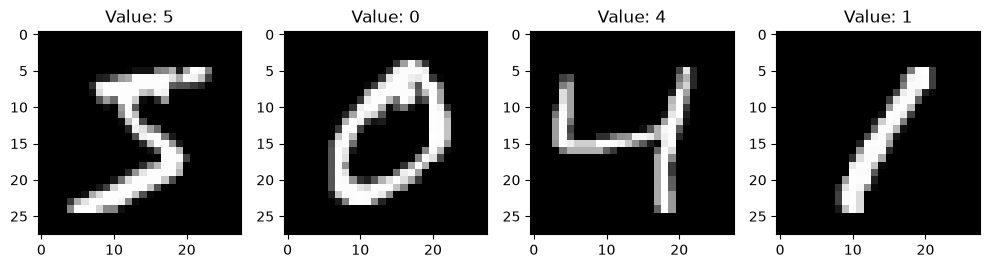

In [490]:
plt.figure(figsize=(10, 3))
for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Value: {y_train[i]}")
    plt.axis("on")

plt.tight_layout()
plt.show()

## Before flattening

In [491]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(60000, 28, 28)
(10000, 28, 28)
(60000,)
(10000,)


## Scale all values btw 0 and 1

In [492]:
X_train=X_train/255
X_test=X_test/255

## Neural Network Architecture

In [493]:
model=Sequential()
model.add(Flatten(input_shape=(28,28)))
model.add(Dense(128,activation="relu"))
model.add(Dropout(0.3))
model.add(Dense(128,activation="relu"))
model.add(Dropout(0.3))
model.add(Dense(10,activation="softmax"))

In [494]:
model.summary()

Model: "sequential_30"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_30 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_76 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_77 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_78 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 118,282 (462.04 KB)

 Trainable params: 118,282 (462.04 KB)

 Non-trainable params: 0 (0.00 B)

In [495]:
model.compile(loss="sparse_categorical_crossentropy",optimizer="Adam",metrics=["accuracy"])

## Traning Model

In [496]:
history=model.fit(X_train,y_train,epochs=10,validation_split=0.2)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8845 - loss: 0.3812 - val_accuracy: 0.9555 - val_loss: 0.1509
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - accuracy: 0.9422 - loss: 0.1939 - val_accuracy: 0.9638 - val_loss: 0.1171
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9528 - loss: 0.1548 - val_accuracy: 0.9685 - val_loss: 0.1051
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9592 - loss: 0.1339 - val_accuracy: 0.9713 - val_loss: 0.0960
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9639 - loss: 0.1193 - val_accuracy: 0.9706 - val_loss: 0.0987
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9670 - loss: 0.1082 - val_accuracy: 0.9737 - val_loss: 0.0886
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9697 - loss: 0.0995 - val_accuracy: 0.9739 - val_loss: 0.0890
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9710 - loss: 0.0937 - 

In [497]:
y_pred=model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [498]:
y_pred=y_pred.argmax(axis=1)

In [499]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.9763

## Comparing Metrics

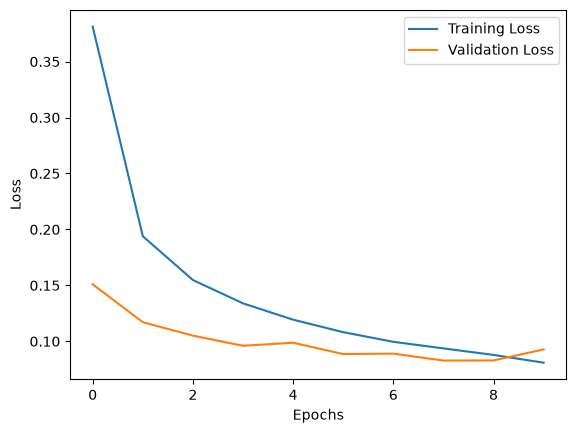

In [500]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

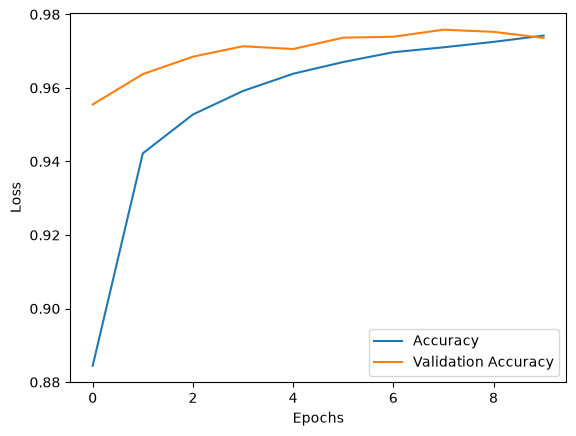

In [501]:
plt.plot(history.history["accuracy"], label="Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

## Accuracy

In [502]:
train_loss, train_acc = model.evaluate(X_train, y_train)
test_loss, test_acc = model.evaluate(X_test, y_test)

print("Training Accuracy:", train_acc)
print("Test Accuracy:", test_acc)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9857 - loss: 0.0462
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9763 - loss: 0.0845
Training Accuracy: 0.9857000112533569
Test Accuracy: 0.9763000011444092


## Prediction

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
Model Prediction :- 1


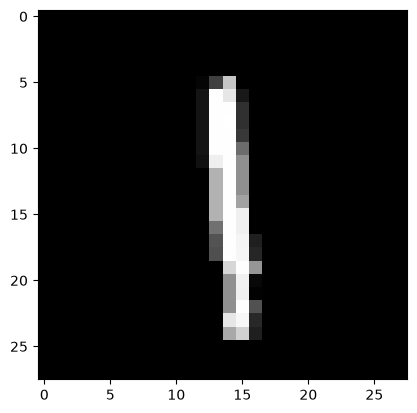

In [503]:
plt.imshow(X_train[8], cmap="gray")
prediction=model.predict(X_train[8].reshape(1,28,28)).argmax(axis=1)
print("Model Prediction :-",prediction[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


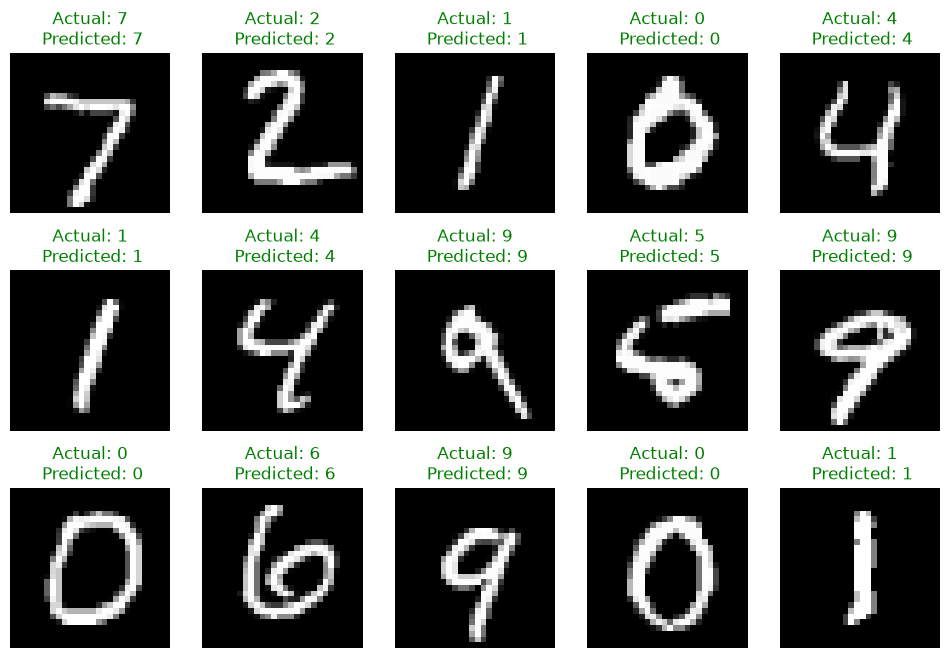

In [504]:
images = X_test[:15]

predictions = model.predict(images)

predicted_digits = np.argmax(predictions, axis=1)

plt.figure(figsize=(12, 8))

for i in range(15):
    plt.subplot(3, 5, i+1)

    plt.imshow(images[i], cmap="gray")

    actual = y_test[i]
    predicted = predicted_digits[i]

    color = "green" if actual == predicted else "red"

    plt.title(
        f"Actual: {actual}\n Predicted: {predicted}",
        color=color
    )

    plt.axis("off")
plt.show()